# Preparazione dei dati

## import librerie 


In [18]:
import os
import random
import torch
import torchvision
from torch.utils.data import Subset
from collections import defaultdict

#Definizione del device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#Definizione dei path
DATA_DIR = "/kaggle/input/unina-machine-learning-24-25-mc-3"
TRAIN_CSV = os.path.join(DATA_DIR, "train.csv")
TRAIN_IMG_DIR = os.path.join(DATA_DIR, "train/train")
TEST_IMG_DIR = os.path.join(DATA_DIR, "test/test")

## Iperparametri

In [3]:
num_epochs = 30
patience_es = 5 #Early Stopping
lr = 0.0005
batch_size = 16

## Funzioni di utility

In [4]:
import os
import torch
from torch.utils.data import Dataset
import pandas as pd
import numpy as np
import cv2
import torchvision.transforms as transforms
import torch.nn as nn
import torchvision.models as models

class Normalize01(torch.nn.Module):
    """Normalizza i valori di un tensore tra 0 e 1, canale per canale."""
    def forward(self, img: torch.Tensor) -> torch.Tensor:
        mi, ma = img.min(), img.max()
        return (img - mi) / (ma - mi) if ma > mi else torch.zeros_like(img)

def lambda_check_range(x):
    return (check_tensor_range(x), x)[1]
    
def check_tensor_range(img):
    """ Controlla se i valori del tensore sono nel range [0,1] dopo ToTensor. """
    if img.min() < 0 or img.max() > 1:
        print("Warning: Tensor values are out of range [0,1] after ToTensor")


class PollinateDataset(Dataset):
    def __init__(self,
                 csv_file: str,
                 dataset_folder: str,
                 channels: tuple = ('T', 'M', 'N'),
                 selected_ids: list = None,
                 transform: torch.nn.Module = None):

        self.df = pd.read_csv(csv_file)
        if selected_ids is not None:
            # Filtra le righe del DataFrame mantenendo solo gli ID in selected_ids
            self.df = self.df[self.df['folder'].isin(selected_ids)].reset_index(drop=True)
        self.dataset_folder = dataset_folder
        self.channels = channels
        self.transform = transform
        self.min_size = (100, 100)

    def __len__(self):
        return len(self.df)

    def pad_image_to_min_size(self, image: np.ndarray, min_size=(100, 100)) -> np.ndarray:
        """Se l'immagine 2D è più piccola di 100×100, aggiunge padding nero ai bordi."""
        h, w = image.shape[:2]
        pad_h = max(0, min_size[0] - h)
        pad_w = max(0, min_size[1] - w)
        top, bottom = pad_h // 2, pad_h - (pad_h // 2)
        left, right = pad_w // 2, pad_w - (pad_w // 2)
        if pad_h > 0 or pad_w > 0:
            image = cv2.copyMakeBorder(image, top, bottom, left, right,
                                       borderType=cv2.BORDER_CONSTANT,
                                       value=0)
        return image

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        sample_id = str(row['folder'])            # es. "000_1"
        label = int(row['class']) if 'class' in row else -1
        folder_path = os.path.join(self.dataset_folder, sample_id)

        imgs = []
        for ch in self.channels:
            path = os.path.join(folder_path, f"{sample_id}_{ch}.npy")
            img = np.load(path)
            img = self.pad_image_to_min_size(img, self.min_size)
            imgs.append(img)

        img_stack = np.stack(imgs, axis=0).astype(np.float32)
        img_tensor = torch.from_numpy(img_stack)  # tensore float32 (3, H, W)

        if self.transform is not None:
            img_tensor = self.transform(img_tensor)
        else:
            if img_tensor.max() > 1.0:
                img_tensor /= 255.0

        return sample_id, img_tensor, label

## Visualizzazione dati

=== Esempio classe 0 ===
ID cella: 001_0 - Classe: 0
Shape tensore (C,H,W): torch.Size([3, 100, 100])
Tipo dato: torch.float32
Valori min: 0.0313725508749485, max: 0.8509804010391235


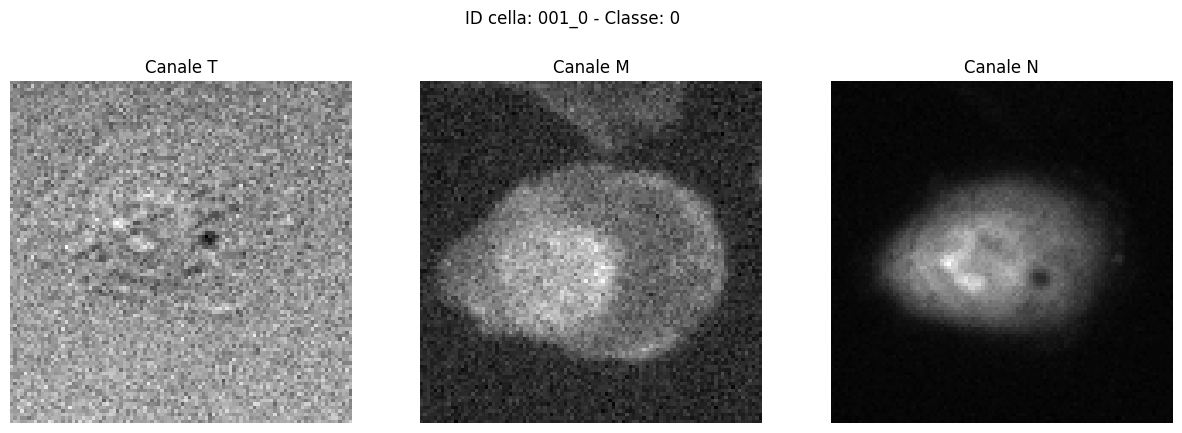

=== Esempio classe 1 ===
ID cella: 000_117 - Classe: 1
Shape tensore (C,H,W): torch.Size([3, 100, 100])
Tipo dato: torch.float32
Valori min: 0.007843137718737125, max: 0.6509804129600525


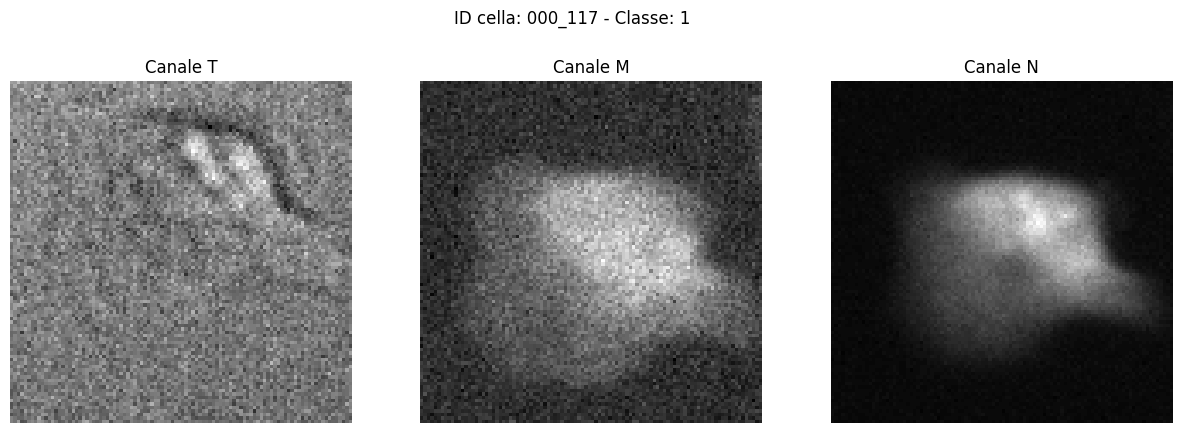

In [5]:
import matplotlib.pyplot as plt

# Carica il dataset di training
dataset_visual = PollinateDataset(csv_file=TRAIN_CSV, dataset_folder=TRAIN_IMG_DIR)

# Trova il primo esempio di classe 0 e di classe 1
idx_0 = next(i for i, (_, _, label) in enumerate(dataset_visual) if label == 0)
idx_1 = next(i for i, (_, _, label) in enumerate(dataset_visual) if label == 1)

def show_sample_info(idx):
    sample_id, img_tensor, label = dataset_visual[idx]
    print(f"ID cella: {sample_id} - Classe: {label}")
    print(f"Shape tensore (C,H,W): {img_tensor.shape}")
    print(f"Tipo dato: {img_tensor.dtype}")
    print(f"Valori min: {img_tensor.min().item()}, max: {img_tensor.max().item()}")
    
    # Visualizza i canali singoli (T, M, N)
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    for i, ch in enumerate(['T', 'M', 'N']):
        axs[i].imshow(img_tensor[i].numpy(), cmap='gray')
        axs[i].set_title(f"Canale {ch}")
        axs[i].axis('off')
    plt.suptitle(f"ID cella: {sample_id} - Classe: {label}")
    plt.show()

print("=== Esempio classe 0 ===")
show_sample_info(idx_0)

print("=== Esempio classe 1 ===")
show_sample_info(idx_1)


## Funzioni trasformazione dati

In [6]:
# Augmentation per il training:
train_transform = transforms.Compose([
    transforms.Lambda(lambda_check_range),
    transforms.RandomHorizontalFlip(p=0.5), #rotazione orizzontale
    transforms.RandomVerticalFlip(p=0.5), #rotazione verticale
    transforms.RandomRotation(degrees=20), #rotazione con angolo random tra -20 e 20
    transforms.RandomResizedCrop(size=224, scale=(0.8, 1.0)), #ritaglio area casuale tra l’80% e il 100% della dimensione originale + resize
    Normalize01()
])

# Solo resize + normalize per validation (e test successivamente):
val_transform = transforms.Compose([
    transforms.Lambda(lambda_check_range),
    transforms.Resize((224, 224)),
    Normalize01()
])

## Lettura file

In [7]:
#Creo dataframe pandas
full_df = pd.read_csv(TRAIN_CSV)

#Creo due liste: ID ed etichette 
folders = full_df['folder'].tolist()
labels = full_df['class'].tolist()

## Calcolo pesi di classe

In [8]:
# Calcolo i pesi di classe
class_counts = full_df['class'].value_counts().to_dict()  # es. {label_0: N0, label_1: N1}
total_samples = sum(class_counts.values())

class_weights = [
    total_samples / class_counts[0],
    total_samples / class_counts[1]
]

#Creo tensore dei pesi e lo assegno al device
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

print("Conteggio classi:", class_counts)
print("Pesi di classe:", class_weights)

Conteggio classi: {1: 4685, 0: 2113}
Pesi di classe: tensor([3.2172, 1.4510], device='cuda:0')


## Creo training e validation

In [9]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader

#Split del dataset, le liste delle etichette non servono verranno lette nella f di utility
train_ids, val_ids, _, _ = train_test_split(
    folders,
    labels,
    test_size=0.20, #20% validation, 80% training
    stratify=labels, #mantengo la stessa proporzione di classi in train e val
    random_state=42
)

#Dataset di training
train_dataset = PollinateDataset(
    csv_file = TRAIN_CSV,
    dataset_folder = TRAIN_IMG_DIR,
    channels = ('T', 'M', 'N'),
    selected_ids = train_ids,
    transform = train_transform
)

#Dataset di validation
val_dataset = PollinateDataset(
    csv_file = TRAIN_CSV,
    dataset_folder = TRAIN_IMG_DIR,
    channels = ('T', 'M', 'N'),
    selected_ids = val_ids,
    transform = val_transform
)

#Creo i dataloader
dataloaders = {
    'train': DataLoader(
        train_dataset,
        batch_size=batch_size, 
        shuffle=True, #shuffle del dataset ad ogni epoca
        num_workers=2, #2 thread per velocizzare caricamento
        pin_memory=True), #migliora trasferimento su GPU
    
    'val':   DataLoader(val_dataset,   batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
}

#calcolo la size dei dataset
dataset_sizes = {
    'train': len(train_dataset),
    'val':   len(val_dataset)
}

# Definizione Architettura

## Resnet50 + fully connected

In [ ]:
#import rete
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

#uso un fully connected per classificazione binaria con Dropout
num_ftrs = model.fc.in_features #numero filtri Resnet50

model.fc = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(num_ftrs, 2) #configuro i filtri per fare classificazione binaria
)

#mappo il modello sul device
model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 160MB/s] 


## Loss, Optimizer e Scheduler

In [11]:
import torch.optim as optim     
from torch.optim.lr_scheduler import ReduceLROnPlateau

#Uso la Cross Entropy come loss function, passo anche i pesi delle classi
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

#Adam optimizer, non congelo i pesi
optimizer = optim.Adam(model.parameters(), lr=lr)

#Import dello scheduler: riduco il learning rate automaticamente se il miglioramento del modello diminuisce
scheduler = ReduceLROnPlateau(
    optimizer,
    mode='max',      # voglio massimizzare accuracy
    factor=0.5,      # dimezza il learning rate
    patience=3       # dopo 3 epoche
)

# Addestramento

## funzione di training

In [12]:
import copy
import time

def train_model(model, criterion, optimizer, scheduler, num_epochs=30, patience_es=5):
    import time
    import copy
    # Salva il tempo di inizio del training
    since = time.time()

    # Salva i pesi migliori del modello (per quando migliora sul validation)
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0  # Miglior accuratezza raggiunta su validation
    epochs_no_improve = 0  # Conta quante epoche consecutive non migliorano

    # Liste per salvare l’andamento delle metriche nel tempo
    train_loss_history = []
    train_acc_history = []
    val_loss_history = []
    val_acc_history = []

    # Loop principale sulle epoche
    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        # Ogni epoca ha due fasi: training e validazione
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  # Attiva dropout, batchnorm ecc.
            else:
                model.eval()   # Disattiva dropout, batchnorm ecc.

            # Inizializza i conteggi di loss e accuracy
            running_loss = 0.0
            running_corrects = 0

            # Itera su tutti i batch del dataloader
            for _, inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)  # Sposta input su GPU 
                labels = labels.to(device)  # Sposta label su GPU 

                # Azzera i gradienti calcolati nel batch precedente
                optimizer.zero_grad()

                # Attiva/disattiva il tracciamento dei gradienti in base alla fase
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)  # Forward pass
                    _, preds = torch.max(outputs, 1)  # Predizione: classe con probabilità più alta
                    loss = criterion(outputs, labels)  # Calcola la loss

                    # Se siamo in training, calcola backward e aggiorna i pesi
                    if phase == 'train':
                        loss.backward() #calcola i gradienti della loss rispetto ai pesi del modello.
                        optimizer.step()

                # Accumula il loss del batch, moltiplicato per il numero di esempi
                running_loss += loss.item() * inputs.size(0)
                # Conta il numero di predizioni corrette
                running_corrects += torch.sum(preds == labels.data)

            # Calcola il loss e l’accuracy medi per l’intera epoca
            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            # Stampa i risultati per questa fase
            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f}  Acc: {epoch_acc:.4f}')

            # Salva le metriche per plot/monitoraggio
            if phase == 'train':
                train_loss_history.append(epoch_loss)
                train_acc_history.append(epoch_acc.item())
            else:
                val_loss_history.append(epoch_loss)
                val_acc_history.append(epoch_acc.item())

                # Aggiorna il learning rate se la validazione non migliora
                scheduler.step(epoch_acc.item())

                # Controlla se la validazione è migliorata rispetto alla migliore finora
                if epoch_acc > best_acc:
                    best_acc = epoch_acc  # Salva nuova migliore accuracy
                    best_model_wts = copy.deepcopy(model.state_dict())  # Salva i pesi migliori
                    epochs_no_improve = 0  # Reset del contatore early stopping
                else:
                    epochs_no_improve += 1  # Altrimenti, aumento il contatore

        # Early stopping: interrompe l’addestramento se non migliora per troppe epoche
        if epochs_no_improve >= patience_es:
            print(f"Early stopping dopo {epoch+1} epoche. Migliore Val Acc: {best_acc:.4f}")
            break

    # Calcola la durata totale del training
    time_elapsed = time.time() - since
    print(f'\nTraining completato in {int(time_elapsed // 60)}m {int(time_elapsed % 60)}s')
    print(f'Migliore Val Acc: {best_acc:.4f}')

    # Ripristina i pesi migliori nel modello (quelli con miglior val_acc)
    model.load_state_dict(best_model_wts)

    # Crea un dizionario con l’andamento delle metriche per ogni epoca
    history = {
        'train_loss': train_loss_history,
        'train_acc': train_acc_history,
        'val_loss': val_loss_history,
        'val_acc': val_acc_history
    }

    return model, history  # Restituisce il modello allenato e lo storico delle metriche


## Avvio il training

In [13]:
model, history = train_model(
    model,
    criterion,
    optimizer,
    scheduler,
    num_epochs=num_epochs,
    patience_es=patience_es
)

# Salvo i pesi migliori 
torch.save(model.state_dict(), "best_resnet50_pollinate.pth")


Epoch 1/30
----------
Train Loss: 0.5331  Acc: 0.7457
Val Loss: 0.4490  Acc: 0.8243

Epoch 2/30
----------
Train Loss: 0.3735  Acc: 0.8444
Val Loss: 0.2731  Acc: 0.8875

Epoch 3/30
----------
Train Loss: 0.3041  Acc: 0.8786
Val Loss: 0.4360  Acc: 0.8882

Epoch 4/30
----------
Train Loss: 0.2701  Acc: 0.8950
Val Loss: 0.3934  Acc: 0.8213

Epoch 5/30
----------
Train Loss: 0.2337  Acc: 0.9086
Val Loss: 0.2673  Acc: 0.9213

Epoch 6/30
----------
Train Loss: 0.2199  Acc: 0.9167
Val Loss: 0.1827  Acc: 0.9471

Epoch 7/30
----------
Train Loss: 0.2079  Acc: 0.9233
Val Loss: 0.1711  Acc: 0.9390

Epoch 8/30
----------
Train Loss: 0.2031  Acc: 0.9252
Val Loss: 0.3392  Acc: 0.9059

Epoch 9/30
----------
Train Loss: 0.1908  Acc: 0.9290
Val Loss: 0.1947  Acc: 0.9243

Epoch 10/30
----------
Train Loss: 0.1812  Acc: 0.9310
Val Loss: 0.2024  Acc: 0.9360

Epoch 11/30
----------
Train Loss: 0.1404  Acc: 0.9467
Val Loss: 0.1840  Acc: 0.9566

Epoch 12/30
----------
Train Loss: 0.1252  Acc: 0.9542
Val Los

inferenza

## Grafici

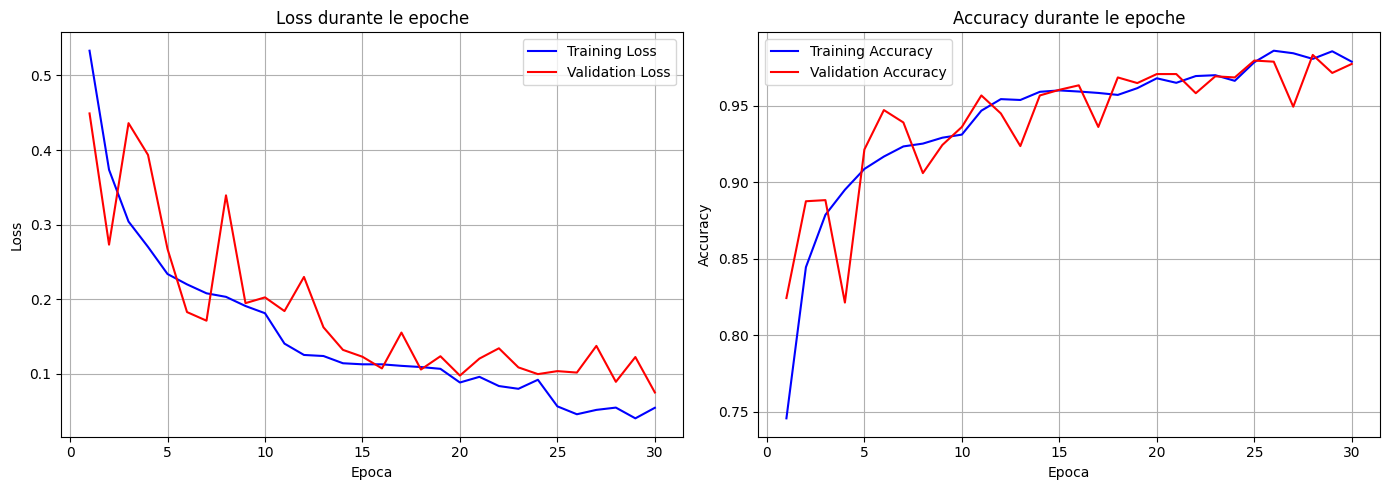

In [14]:
import matplotlib.pyplot as plt

def plot_training_history(history):
    """
    Visualizza le curve di loss e accuracy per train e validation.
    
    history: dict restituito da train_model, con chiavi:
        - 'train_loss', 'val_loss'
        - 'train_acc', 'val_acc'
    """
    epochs = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(14, 5))

    # ---- Plot Loss ----
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], 'b-', label='Training Loss')
    plt.plot(epochs, history['val_loss'], 'r-', label='Validation Loss')
    plt.title('Loss durante le epoche')
    plt.xlabel('Epoca')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # ---- Plot Accuracy ----
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['train_acc'], 'b-', label='Training Accuracy')
    plt.plot(epochs, history['val_acc'], 'r-', label='Validation Accuracy')
    plt.title('Accuracy durante le epoche')
    plt.xlabel('Epoca')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_training_history(history)


# Testing

## funzione pollinate dataset adattata (senza label)

In [16]:
import os
import numpy as np
import torch
from torch.utils.data import Dataset
import cv2

class TestPollinateDataset(Dataset):
    def __init__(self,
                 dataset_folder: str,
                 channels: tuple = ('T', 'M', 'N'),
                 selected_ids: list = None,
                 transform: torch.nn.Module = None):
        
        self.dataset_folder = dataset_folder
        self.channels = channels
        self.transform = transform
        self.min_size = (100, 100)

        # Prende le sottocartelle come ID dei campioni
        all_ids = sorted(os.listdir(dataset_folder))
        if selected_ids is not None:
            self.ids = [i for i in all_ids if i in selected_ids]
        else:
            self.ids = all_ids

    def __len__(self):
        return len(self.ids)

    def pad_image_to_min_size(self, image: np.ndarray, min_size=(100, 100)) -> np.ndarray:
        h, w = image.shape[:2]
        pad_h = max(0, min_size[0] - h)
        pad_w = max(0, min_size[1] - w)
        top, bottom = pad_h // 2, pad_h - (pad_h // 2)
        left, right = pad_w // 2, pad_w - (pad_w // 2)
        if pad_h > 0 or pad_w > 0:
            image = cv2.copyMakeBorder(image, top, bottom, left, right,
                                       borderType=cv2.BORDER_CONSTANT, value=0)
        return image

    def __getitem__(self, idx: int):
        sample_id = self.ids[idx]
        folder_path = os.path.join(self.dataset_folder, sample_id)

        imgs = []
        for ch in self.channels:
            path = os.path.join(folder_path, f"{sample_id}_{ch}.npy")
            img = np.load(path)
            img = self.pad_image_to_min_size(img, self.min_size)
            imgs.append(img)

        img_stack = np.stack(imgs, axis=0).astype(np.float32)
        img_tensor = torch.from_numpy(img_stack)

        if self.transform:
            img_tensor = self.transform(img_tensor)
        else:
            if img_tensor.max() > 1.0:
                img_tensor /= 255.0

        return sample_id, img_tensor


## creo dataloader, carico i pesi migliori e faccio inferenza

In [20]:
from torch.utils.data import DataLoader
import pandas as pd

# Dataset test 
test_dataset = TestPollinateDataset(
    dataset_folder=TEST_IMG_DIR,
    transform=val_transform
)

# Dataloader test
test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

# Carico i pesi del modello addestrato
model.load_state_dict(torch.load("best_resnet50_pollinate.pth", map_location=device))
model.eval()

# Inferenza
results = []
with torch.no_grad():
    for ids, inputs in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        results.extend(zip(ids, preds.cpu().numpy()))

# Salvataggio predizioni
submission_df = pd.DataFrame(results, columns=["Img", "class"])
submission_df.to_csv("submission_finale.csv", index=False)
